# Notebook 3 — Resultados

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Cuaderno de **resultados**, sobre el export real de ventas de **El Café que te
Conté**: métricas técnicas finales, métricas de negocio, visualizaciones, el
indicador de riesgo por producto y los dos entregables que consume el resto del
proyecto — `metrics/metrics.json` (para la API/CI) y `reports/reporte_ejecutivo.md`
(para una persona no técnica del negocio).

## 1. Carga de modelos y datos de test

In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from practica3.features import (  # noqa: E402
    FEATURE_COLS,
    HORIZONTES,
    etiquetas_negocio_top_n,
    split_temporal,
)
from practica3.inference import DemandPredictor  # noqa: E402

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

MODELS_DIR = ROOT / "models"
METRICS_DIR = ROOT / "metrics"
REPORTS_DIR = ROOT / "reports"
METRICS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "processed" / "dataset_features.parquet")
features_meta = json.loads((ROOT / "data" / "processed" / "features.json").read_text())
metadata = json.loads((MODELS_DIR / "metadata.json").read_text())
residuales = json.loads((MODELS_DIR / "residuales.json").read_text())
svr_models = {h: joblib.load(MODELS_DIR / f"svr_h{h}.joblib") for h in HORIZONTES}
svc_alerta = joblib.load(MODELS_DIR / "svc_alerta.joblib")
isolation_forest = joblib.load(MODELS_DIR / "isolation_forest.joblib")

# El SVR y el SVC/IsolationForest usan conjuntos de features distintos
# (ver nota de diseño en src/practica3/inference.py).
FEATURE_COLS_SVR = metadata["feature_cols_svr"]
FEATURE_COLS_SVC_ISO = metadata["feature_cols_svc_iso"]

# Reconstruye los mismos splits del notebook 2 (determinista, sin aleatoriedad)
splits = {}
for h in HORIZONTES:
    train, test, corte = split_temporal(df, target_col=f"target_h{h}", feature_cols=FEATURE_COLS_SVR)
    X_test = test[FEATURE_COLS_SVR].values
    y_test = test[f"target_h{h}"].values
    pred_test = svr_models[h].predict(X_test)
    splits[h] = {"train": train, "test": test, "X_test": X_test, "y_test": y_test, "pred_test": pred_test}

# Set de test de SVC/IsolationForest (horizonte 1, mismas filas, más columnas)
X_test_svc_iso = splits[1]["test"][FEATURE_COLS_SVC_ISO].values

print("Modelos y test sets recargados para horizontes:", HORIZONTES)
print(f"Features SVR: {len(FEATURE_COLS_SVR)} de {len(FEATURE_COLS)} candidatas | Features SVC/Iso: {len(FEATURE_COLS_SVC_ISO)}")

Modelos y test sets recargados para horizontes: (1, 3, 7)
Features SVR: 9 de 24 candidatas | Features SVC/Iso: 24


## 2. Métricas técnicas finales

Tabla multi-horizonte, tal como quedó guardada por el notebook 2. El contexto
histórico (Práctica 2 / Informe SVM, dataset sintético) se cita aparte — **no es
comparable numéricamente** (productos, escala y ruido distintos).

In [2]:
tabla_horizontes = pd.DataFrame(metadata["metricas"]).T
tabla_horizontes.index.name = "horizonte"
print("Métricas por horizonte (Práctica 3, datos reales):")
print(tabla_horizontes.round(3).to_string())

ctx = metadata.get("contexto_historico_no_comparable", {})
if ctx.get("practica_2_sintetico"):
    print("\nContexto histórico (dataset sintético — NO comparable numéricamente):")
    print("  Práctica 2   :", ctx["practica_2_sintetico"])
    print("  Informe SVM  :", ctx["informe_svm_sintetico"])

Métricas por horizonte (Práctica 3, datos reales):
             rmse    mae     r2
horizonte                      
1          10.942  7.753  0.464
3          10.984  7.764  0.460
7          10.872  7.458  0.465

Contexto histórico (dataset sintético — NO comparable numéricamente):
  Práctica 2   : {'rmse_test': 7.1248, 'mae_test': 5.2128, 'r2_test': 0.2802}
  Informe SVM  : {'rmse': 5.109958252434942, 'mae': 3.6461547234933778, 'r2': 0.42384687405845634}


## 3. Real vs predicho, por horizonte

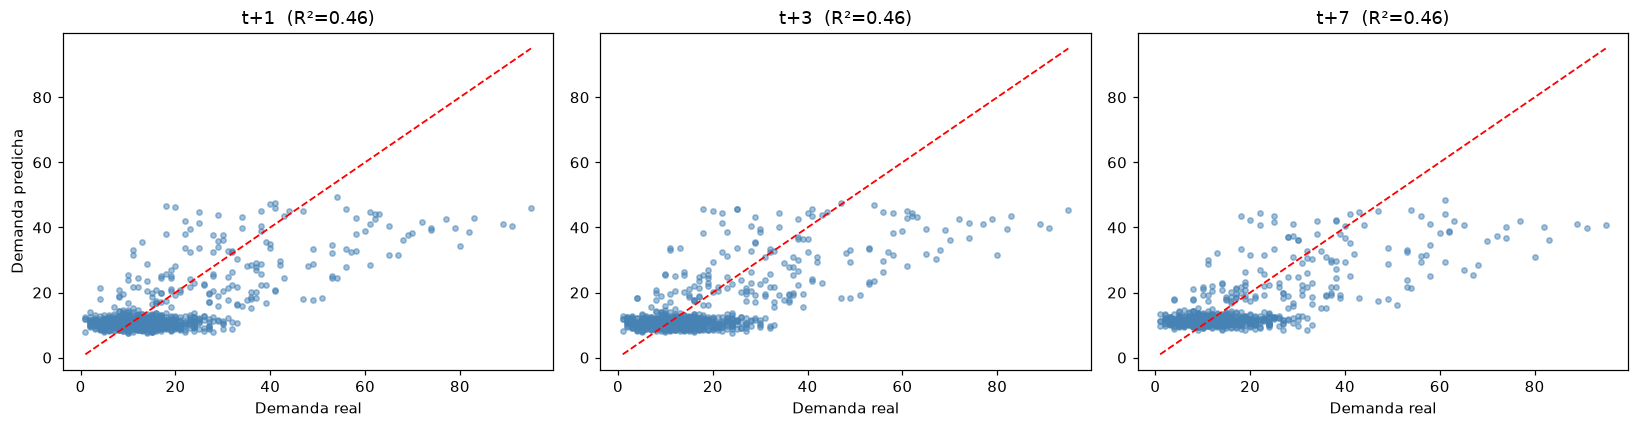

In [3]:
fig, axes = plt.subplots(1, len(HORIZONTES), figsize=(5 * len(HORIZONTES), 4))
for ax, h in zip(axes, HORIZONTES):
    y_true, y_pred = splits[h]["y_test"], splits[h]["pred_test"]
    ax.scatter(y_true, y_pred, s=12, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1.2)
    r2 = metadata["metricas"][str(h)]["r2"]
    ax.set_title(f"t+{h}  (R²={r2:.2f})")
    ax.set_xlabel("Demanda real"); ax.set_ylabel("Demanda predicha" if h == HORIZONTES[0] else "")
plt.tight_layout(); plt.show()

## 4. Serie temporal con escenarios (producto top, horizonte t+1)

Demanda real vs predicha del producto más vendido en el periodo de test, con la
banda **conservador–optimista** calculada en el notebook 2 (§V.D del feedback:
"mostrar intervalos de confianza" y "escenarios optimista/esperado/conservador").

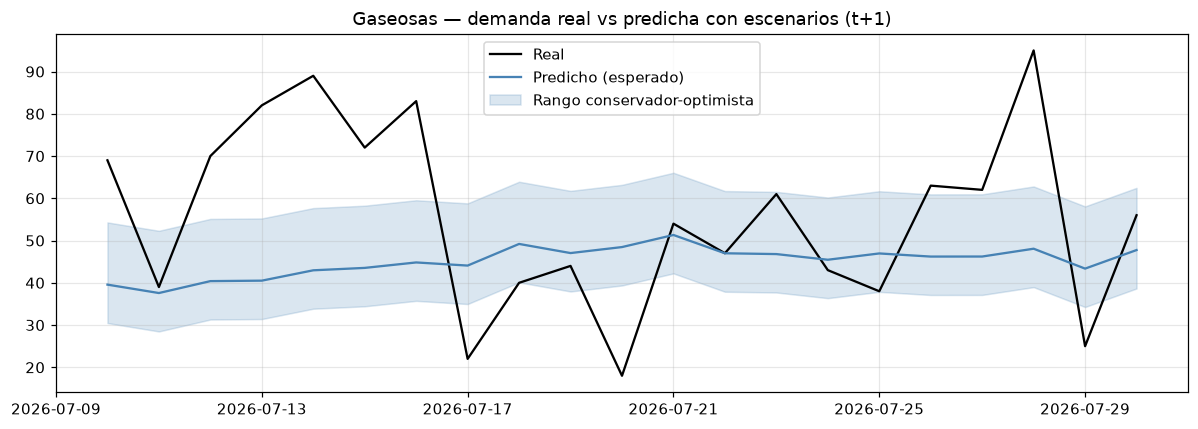

In [4]:
predictor = DemandPredictor()

test_h1 = splits[1]["test"]
pid_top = test_h1.groupby("product_id")["cantidad_vendida"].sum().idxmax()
fechas_top = test_h1[test_h1["product_id"] == pid_top].sort_values("fecha")["fecha"]

registros = [predictor.predecir(int(pid_top), str(f.date()), horizonte=1) for f in fechas_top]
serie = pd.DataFrame(registros)
reales = test_h1[test_h1["product_id"] == pid_top].sort_values("fecha").set_index("fecha")["target_h1"]
serie = serie.set_index(pd.to_datetime(serie["fecha_referencia_datos"]))
nombre_top = test_h1.loc[test_h1["product_id"] == pid_top, "nombre"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(reales.index, reales.values, label="Real", color="black", lw=1.5)
ax.plot(serie.index, serie["prediccion_esperada"], label="Predicho (esperado)", color="steelblue", lw=1.5)
ax.fill_between(serie.index, serie["escenario_conservador"], serie["escenario_optimista"],
                color="steelblue", alpha=0.2, label="Rango conservador-optimista")
ax.set_title(f"{nombre_top} — demanda real vs predicha con escenarios (t+1)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Métricas de negocio — ingresos en riesgo (precio real)

Punto §V.1 del feedback: métricas orientadas al negocio, no solo técnicas. A
diferencia de la iteración sintética (que usaba costos de ejemplo inventados por
categoría), ahora hay `precio_unitario` **real** por producto — se usa
directamente, sin inventar márgenes: error de predicción × precio real = ingreso en
riesgo. Relevante para El Café que te Conté: varios de sus productos (Pasteles,
Desayunos) son perecederos — el feedback empresarial (`Feedback Empresas.pdf`
§III.A) señaló explícitamente esa preocupación.

In [5]:
precio_por_producto = df.groupby("product_id")["precio_promedio"].mean()

test_h1 = splits[1]["test"].copy()
test_h1["pred"] = splits[1]["pred_test"]
test_h1["pred_naive"] = test_h1["lag_7"]  # baseline: demanda de hace 7 dias
test_h1["precio"] = test_h1["product_id"].map(precio_por_producto)

def ingresos_en_riesgo(df_, col_pred):
    quiebre = (df_["target_h1"] - df_[col_pred]).clip(lower=0) * df_["precio"]  # demanda no atendida
    sobrante = (df_[col_pred] - df_["target_h1"]).clip(lower=0) * df_["precio"]  # preparado de más / posible merma
    return float(quiebre.sum()), float(sobrante.sum())

quiebre_modelo, sobrante_modelo = ingresos_en_riesgo(test_h1, "pred")
quiebre_naive, sobrante_naive = ingresos_en_riesgo(test_h1, "pred_naive")

resumen_negocio = pd.DataFrame([
    {"escenario": "Baseline ingenuo (lag_7)", "ingreso_perdido_quiebre": quiebre_naive,
     "valor_sobrante_posible_merma": sobrante_naive, "total_en_riesgo": quiebre_naive + sobrante_naive},
    {"escenario": "Modelo Práctica 3 (SVR t+1)", "ingreso_perdido_quiebre": quiebre_modelo,
     "valor_sobrante_posible_merma": sobrante_modelo, "total_en_riesgo": quiebre_modelo + sobrante_modelo},
]).round(2)
reduccion_pct = 100 * (1 - resumen_negocio.loc[1, "total_en_riesgo"] / resumen_negocio.loc[0, "total_en_riesgo"])
print(resumen_negocio.to_string(index=False))
print(f"\nReducción de ingresos en riesgo usando el modelo vs baseline ingenuo: {reduccion_pct:.1f}%")
print("(basado en precio_unitario real del periodo de test, sin márgenes inventados)")

                  escenario  ingreso_perdido_quiebre  valor_sobrante_posible_merma  total_en_riesgo
   Baseline ingenuo (lag_7)                 18091.72                      14720.07         32811.79
Modelo Práctica 3 (SVR t+1)                 16027.67                       6136.33         22163.99

Reducción de ingresos en riesgo usando el modelo vs baseline ingenuo: 32.5%
(basado en precio_unitario real del periodo de test, sin márgenes inventados)


## 6. Detección de anomalías — resumen en test

In [6]:
pred_anom = isolation_forest.predict(X_test_svc_iso)
test_h1["anomalia"] = pred_anom == -1
n_anom = int(test_h1["anomalia"].sum())
print(f"Compras/ventas marcadas como atípicas en test: {n_anom} / {len(test_h1)} ({n_anom/len(test_h1):.1%})")
cols = ["fecha", "product_id", "nombre", "cantidad_vendida", "target_h1", "pred"]
test_h1[test_h1["anomalia"]][cols].sort_values("fecha").head(10)

Compras/ventas marcadas como atípicas en test: 72 / 688 (10.5%)


,fecha,product_id,nombre,cantidad_vendida,target_h1,pred
8,2026-07-10,15,Gaseosas,34,69.0,37.608836
23,2026-07-10,7,Café,22,79.0,39.776209
45,2026-07-11,28,Smoothies,42,36.0,28.550402
46,2026-07-11,15,Gaseosas,69,39.0,35.619069
47,2026-07-11,7,Café,79,30.0,36.103681
61,2026-07-11,18,Jugos,48,20.0,28.267234
94,2026-07-12,15,Gaseosas,39,70.0,38.438006
96,2026-07-12,7,Café,30,74.0,39.701034
115,2026-07-13,28,Smoothies,61,42.0,29.764187
117,2026-07-13,7,Café,74,74.0,39.066270


## 7. Importancia de variables — resumen final

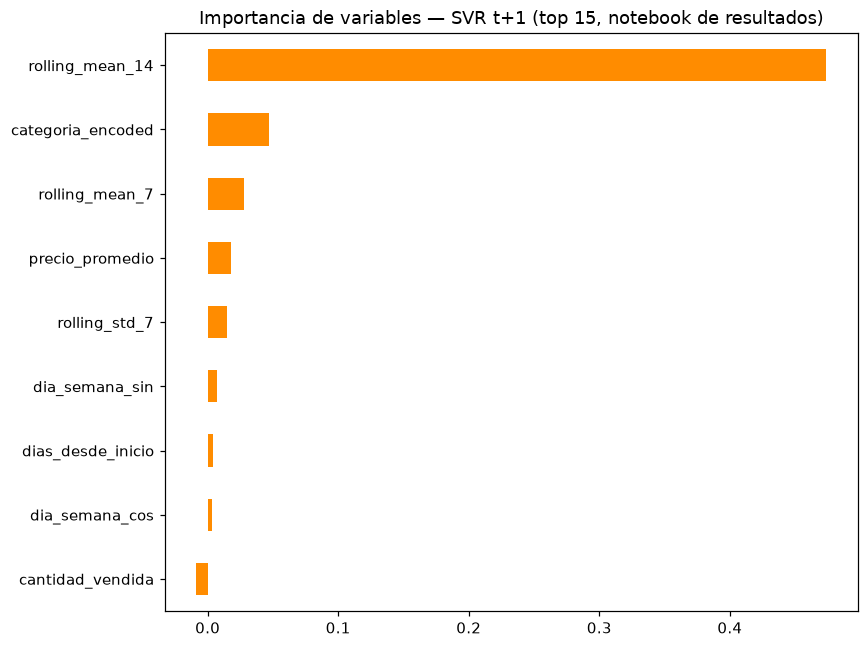

Top 5 variables más influyentes:
  rolling_mean_14           0.4740
  categoria_encoded         0.0467
  rolling_mean_7            0.0279
  precio_promedio           0.0175
  rolling_std_7             0.0151


In [7]:
perm = permutation_importance(
    svr_models[1], splits[1]["X_test"], splits[1]["y_test"], n_repeats=20, random_state=42, n_jobs=-1
)
importancia = pd.Series(perm.importances_mean, index=FEATURE_COLS_SVR).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importancia.head(15).iloc[::-1].plot.barh(ax=ax, color="darkorange")
ax.set_title("Importancia de variables — SVR t+1 (top 15, notebook de resultados)")
plt.tight_layout(); plt.show()

top5 = importancia.head(5)
print("Top 5 variables más influyentes:")
for nombre, val in top5.items():
    print(f"  {nombre:25s} {val:.4f}")

## 8. Proceso de XAI (SHAP) — de la predicción al dato original

Punto 3.5 de la guía: formalizar, en pasos, un proceso de explicación que
justifique una predicción individual del SVR **hacia atrás, hasta la data
original** — no solo la importancia global de variables (sección 7), sino el
porqué de un caso puntual.

**Proceso (6 pasos):**

1. **Elegir la instancia**: un producto y una fecha de referencia concretos.
2. **Recuperar su fila del dataset procesado** (`dataset_features.parquet`) —
   los valores originales de las 9 features que usa el SVR, sin escalar.
3. **Calcular el valor base del modelo** (`expected_value`): la predicción
   promedio del SVR sobre una muestra de referencia del set de entrenamiento.
4. **Calcular los valores SHAP de la instancia** con `KernelExplainer` sobre el
   pipeline completo (`StandardScaler` + `SVR`) — model-agnostic, por eso sirve
   con un kernel no lineal (RBF) donde no hay pesos que leer directamente.
5. **Visualizar** con un *waterfall plot*: cada feature empuja la predicción
   hacia arriba o abajo desde el valor base, en las unidades originales de la
   variable (no las escaladas).
6. **Trazar hacia la data original real**: bajar desde la fila del dataset
   procesado hasta los tickets de venta crudos (`ventas.csv`) que efectivamente
   componen esa fila — para que la explicación no se quede en un número
   abstracto, sino que conecte con ventas reales de la cafetería.

Se usa `shap.KernelExplainer` (no `shap.LinearExplainer` ni `TreeExplainer`)
porque el SVR con kernel RBF no es lineal ni basado en árboles — Kernel SHAP
funciona con cualquier `predict`, a costo de más cómputo (por eso el background
de referencia se limita a 50 filas).

1) Instancia: Café — fecha de referencia 2026-07-25
2-3) Predicción t+1: 40.50 u.  |  Valor base del modelo: 17.01 u.
4) Contribución SHAP por variable (ordenadas por magnitud):
          feature                                       concepto_negocio  valor_original   shap
  rolling_mean_14       El promedio de ventas de las últimas dos semanas          50.357 21.576
dias_desde_inicio          La tendencia general del negocio en el tiempo         115.000 -2.908
categoria_encoded                              La categoría del producto           0.000  2.314
   rolling_mean_7              El promedio de ventas de la última semana          35.857  1.875
   dia_semana_sin                                Qué día de la semana es          -0.975 -1.164
    rolling_std_7 Qué tan irregulares fueron las ventas la última semana          13.570  0.901
  precio_promedio                El precio promedio del producto ese día           2.893  0.830
 cantidad_vendida                                   Cu

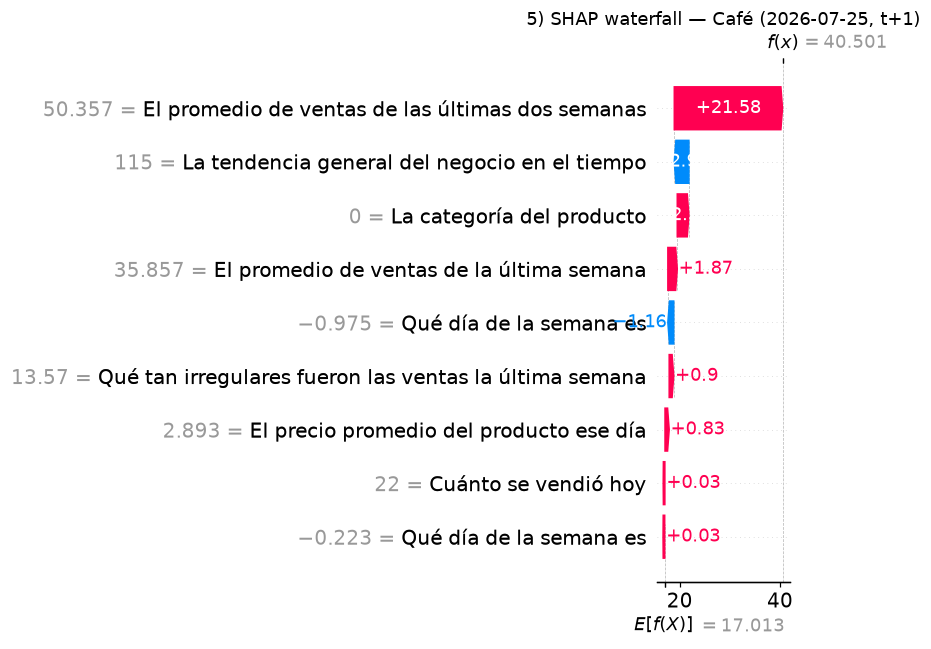

In [8]:
import shap

from practica3.features import FEATURE_LABELS_NEGOCIO  # noqa: E402

FEATURE_LABELS = {c: FEATURE_LABELS_NEGOCIO.get(c, c) for c in FEATURE_COLS_SVR}

ventas_crudas = pd.read_csv(ROOT / "data" / "raw" / "ventas.csv")
ventas_crudas["fecha"] = pd.to_datetime(ventas_crudas["fecha_completa"], format="%d/%m/%Y")

background = shap.sample(splits[1]["train"][FEATURE_COLS_SVR], 50, random_state=42)
explainer_svr = shap.KernelExplainer(svr_models[1].predict, background)


def explicar_prediccion(product_id: int, fecha: str, horizonte: int = 1):
    """Pasos 2-6 del proceso: recupera la fila original, calcula SHAP y arma
    la trazabilidad hasta los tickets de venta crudos de esa fecha-producto."""
    fecha_ts = pd.Timestamp(fecha)
    fila = df[(df["product_id"] == product_id) & (df["fecha"] == fecha_ts)]
    if fila.empty:
        raise ValueError(f"Sin fila para product_id={product_id} en {fecha}")
    fila = fila.iloc[0]
    nombre = fila["nombre"]

    X = fila[FEATURE_COLS_SVR].to_frame().T.astype(float)
    modelo = svr_models[horizonte]
    pred = float(modelo.predict(X.values)[0])
    shap_vals = explainer_svr.shap_values(X, nsamples=200, silent=True)[0]

    tabla = (
        pd.DataFrame({
            "feature": FEATURE_COLS_SVR,
            "concepto_negocio": [FEATURE_LABELS[c] for c in FEATURE_COLS_SVR],
            "valor_original": X.iloc[0].to_numpy(),
            "shap": shap_vals,
        })
        .reindex(np.argsort(-np.abs(shap_vals)))
        .reset_index(drop=True)
    )
    tickets = ventas_crudas[
        (ventas_crudas["producto"] == nombre) & (ventas_crudas["fecha"] == fecha_ts)
    ][["id_ticket", "hora_exacta", "variante_o_sabor", "cantidad_vendida", "precio_unitario"]]

    explicacion = shap.Explanation(
        values=shap_vals,
        base_values=explainer_svr.expected_value,
        data=X.iloc[0].to_numpy(),
        feature_names=[FEATURE_LABELS[c] for c in FEATURE_COLS_SVR],
    )
    return {
        "producto": nombre, "fecha_referencia": fecha_ts, "prediccion_h": pred,
        "tabla_shap": tabla, "tickets_crudos": tickets, "explicacion": explicacion,
    }


# Demo del proceso completo sobre un solo caso: Café, 2026-07-25
demo = explicar_prediccion(product_id=7, fecha="2026-07-25", horizonte=1)
nombre_demo = demo["producto"]
fecha_demo = demo["fecha_referencia"].date()
print(f"1) Instancia: {nombre_demo} — fecha de referencia {fecha_demo}")
print(f"2-3) Predicción t+1: {demo['prediccion_h']:.2f} u.  |  Valor base del modelo: {explainer_svr.expected_value:.2f} u.")
print("4) Contribución SHAP por variable (ordenadas por magnitud):")
print(demo["tabla_shap"].round(3).to_string(index=False))
print(f"\n6) Trazabilidad a la data original — tickets del {fecha_demo} "
      f"para '{nombre_demo}' que componen su `cantidad_vendida` de ese día:")
print(demo["tickets_crudos"].to_string(index=False))

shap.plots.waterfall(demo["explicacion"], show=False)
plt.title(f"5) SHAP waterfall — {demo['producto']} ({demo['fecha_referencia'].date()}, t+1)")
plt.tight_layout(); plt.show()

## 9. XAI aplicado — dos ejemplos contrastantes

Punto 3.6 de la guía: aplicar el proceso a **2 ejemplos distintos**, cada uno
contrastando dos productos con roles de negocio opuestos. Para que la
comparación sea justa, los 4 usan la **misma fecha de referencia** —
2026-07-25 (sábado) prediciendo la demanda del 2026-07-26 (domingo).

- **Ejemplo 1 — perecible vs. no perecible**: *Cheesecake de Frutos Rojos*
  (Pasteles, lácteo/fruta fresca, vida útil corta — el negocio no puede
  sobre-producir sin arriesgar merma) vs. *Agua* (Bebidas, embotellada, vida
  útil larga — el negocio puede sobre-stockear sin ese riesgo).
- **Ejemplo 2 — popular en fin de semana vs. canasta básica**: *Tres Leches*
  (Pasteles, ratio demanda fin de semana/entre semana = 1.14 en todo el
  histórico — postre para compartir) vs. *Café* (Bebidas, ratio ≈ 1.00 y la
  menor variabilidad relativa del menú — consumo diario constante,
  independiente del día).

Ejemplo 1 — perecible (Cheesecake de Frutos Rojos): predicción t+1 = 9.42 u. (base = 17.01 u.)


Ejemplo 1 — no perecible (Agua): predicción t+1 = 22.67 u. (base = 17.01 u.)


Ejemplo 2 — popular fin de semana (Tres Leches): predicción t+1 = 10.95 u. (base = 17.01 u.)


Ejemplo 2 — canasta básica (Café): predicción t+1 = 40.50 u. (base = 17.01 u.)


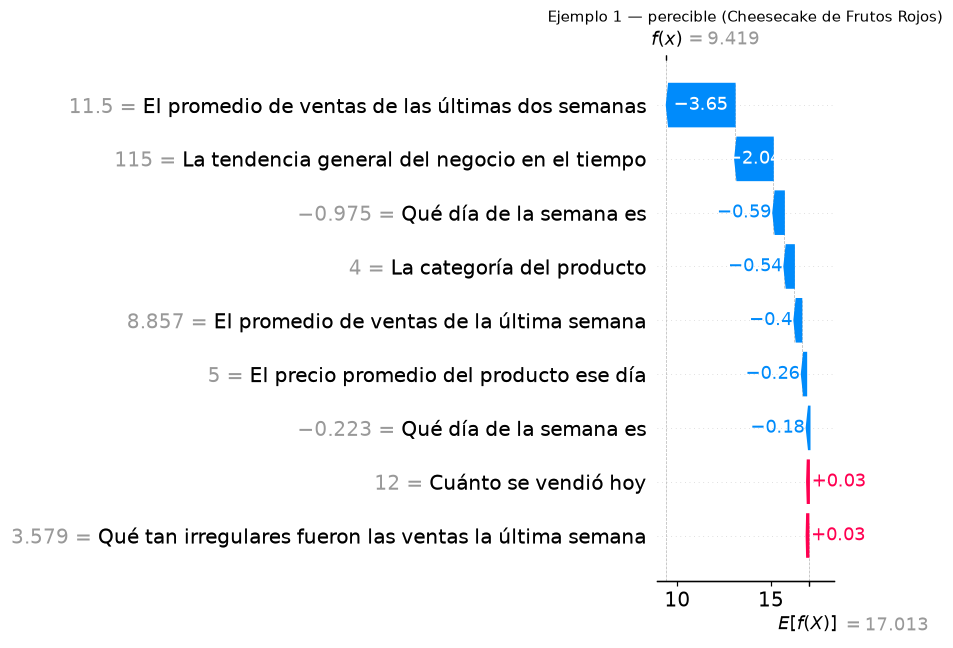

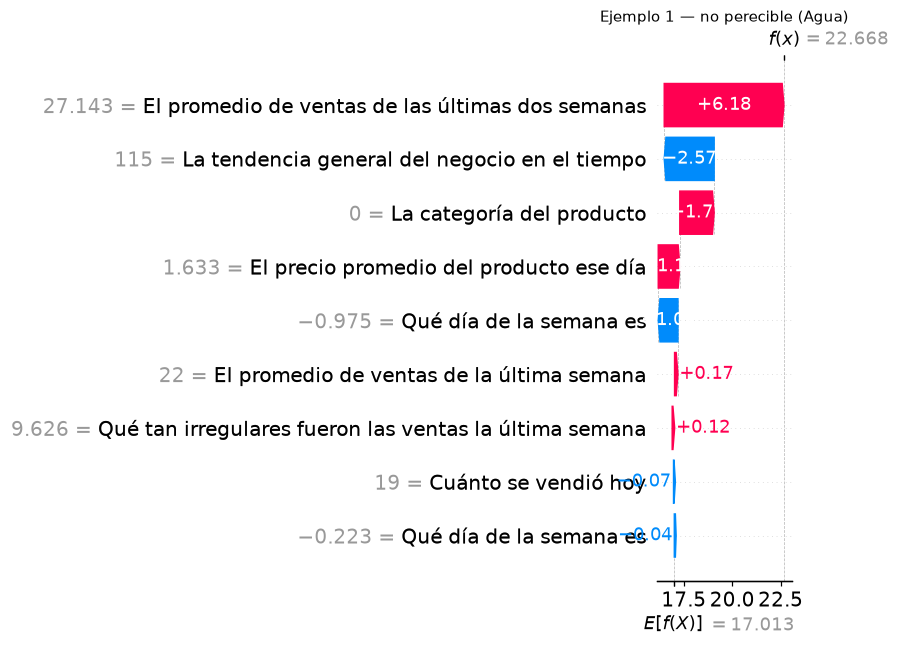

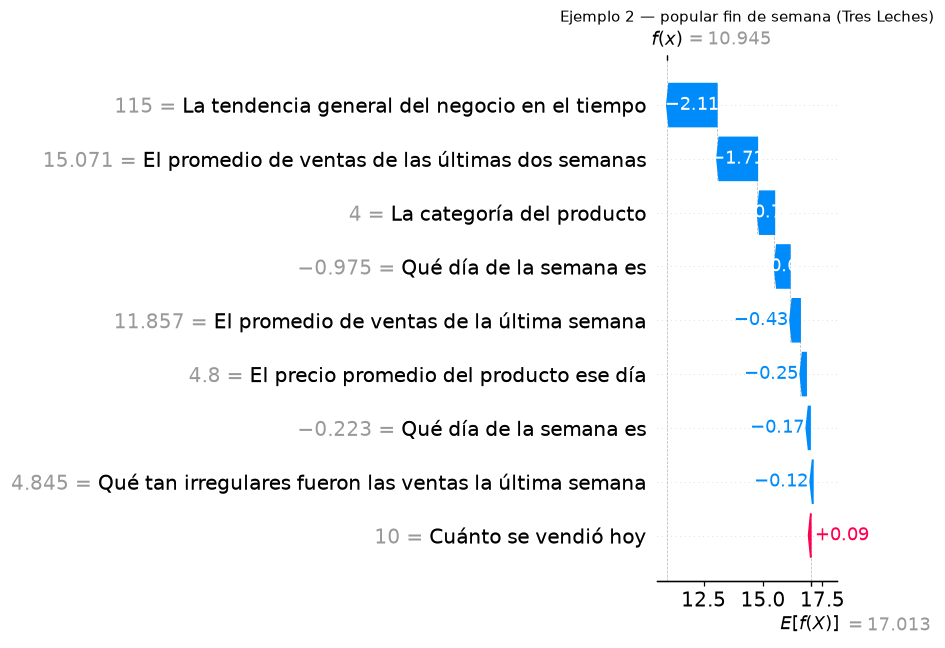

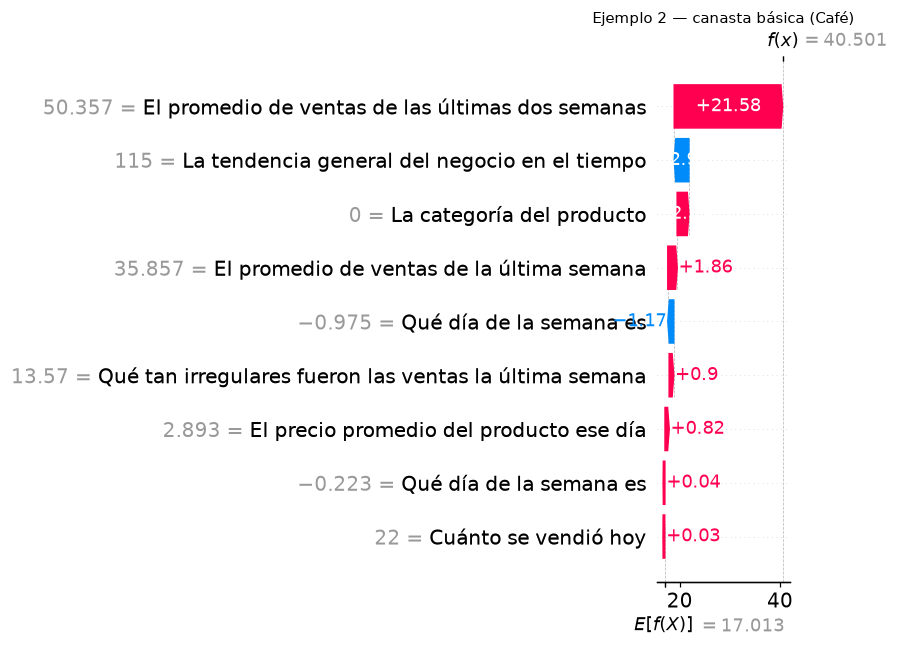

In [9]:
FECHA_REF = "2026-07-25"  # sábado -> predice el domingo 2026-07-26 (misma fecha para los 4 productos)
EJEMPLOS = {
    "Ejemplo 1 — perecible (Cheesecake de Frutos Rojos)": 8,
    "Ejemplo 1 — no perecible (Agua)": 2,
    "Ejemplo 2 — popular fin de semana (Tres Leches)": 31,
    "Ejemplo 2 — canasta básica (Café)": 7,
}

resultados_xai = {}
for etiqueta, pid in EJEMPLOS.items():
    r = explicar_prediccion(product_id=pid, fecha=FECHA_REF, horizonte=1)
    resultados_xai[etiqueta] = r
    print(f"{etiqueta}: predicción t+1 = {r['prediccion_h']:.2f} u. (base = {explainer_svr.expected_value:.2f} u.)")

for etiqueta, r in resultados_xai.items():
    shap.plots.waterfall(r["explicacion"], show=False)
    plt.title(etiqueta, fontsize=10)
    plt.tight_layout(); plt.show()

**Lectura de los 4 casos** (con los valores SHAP reales de esta corrida):

- En los 4 productos, `rolling_mean_14` (promedio de las últimas dos semanas)
  es la variable que más empuja la predicción — consistente con la
  importancia global de la sección 7. Pero el **peso relativo de las demás
  variables cambia según el rol del producto**, que es justamente lo que
  distingue a un buen proceso de XAI de solo mirar la importancia global:
- **Perecible vs. no perecible**: en *Cheesecake* la razón entre el aporte de
  `rolling_mean_7` (una semana) y `rolling_mean_14` (dos semanas) es ~0.11
  (11%); en *Agua* es ~0.03 (3%). El modelo apoya proporcionalmente más su
  predicción en la señal **más reciente** para el producto perecible —
  coherente con que su demanda es más volátil y el negocio no puede
  darse el lujo de mirar solo el promedio largo sin arriesgar merma.
- **Popular fin de semana vs. canasta básica**: el aporte conjunto de
  `dia_semana_sin` + `dia_semana_cos` (qué día de la semana es) representa
  ~13% del total de |SHAP| en *Tres Leches*, contra ~3.5% en *Café*. El día
  de la semana influye casi 4 veces más en la predicción del postre social
  que en la del consumo diario constante — el propio modelo, sin que se le
  diga nada de antemano, "descubrió" el patrón que motivó a elegir estos dos
  productos como ejemplo.
- La trazabilidad hasta los tickets crudos (paso 6) confirma que
  `cantidad_vendida` de cada fila corresponde exactamente a la suma de las
  líneas de venta reales de ese producto ese día — la explicación no se queda
  en features abstractas, se puede verificar contra la venta real.

## 10. Indicador de riesgo — semáforo por producto

Punto §V.7 del feedback: un indicador fácil de interpretar. Para cada producto se
calcula la predicción de mañana (t+1) a partir de su última fecha disponible, con su
nivel de riesgo (verde/amarillo/rojo) según ancho del intervalo y calidad de datos.

In [10]:
EMOJI_RIESGO = {"verde": "🟢", "amarillo": "🟡", "rojo": "🔴"}
fecha_max = df["fecha"].max()
semaforo = []
for pid in sorted(df["product_id"].unique()):
    r = predictor.predecir(int(pid), str(fecha_max.date()), horizonte=1)
    nombre = df.loc[df["product_id"] == pid, "nombre"].iloc[0]
    semaforo.append({
        "product_id": pid, "nombre": nombre,
        "prediccion_manana": r["prediccion_esperada"],
        "rango": f"{r['escenario_conservador']}–{r['escenario_optimista']}",
        "nivel_riesgo": r["nivel_riesgo"],
        "datos_historicos_suficientes": r["datos_historicos_suficientes"],
        "alerta_anomalia": r["alerta_anomalia"],
        "riesgo": EMOJI_RIESGO[r["nivel_riesgo"]] + " " + r["nivel_riesgo"],
        "alerta_alta_demanda": r["alerta_alta_demanda"],
    })
semaforo_df = pd.DataFrame(semaforo)
print(semaforo_df.drop(columns=["nivel_riesgo"]).to_string(index=False))

 product_id                            nombre  prediccion_manana       rango  datos_historicos_suficientes  alerta_anomalia     riesgo  alerta_alta_demanda
          1                       Affo Cookie               9.63  0.54–24.35                          True            False 🟡 amarillo                False
          2                              Agua              26.49  17.4–41.21                          True            False 🟡 amarillo                False
          3                     Avocado Toast              11.14  2.05–25.86                          True            False 🟡 amarillo                False
          4              Bacon Egg and Cheese              10.09   1.0–24.82                          True            False 🟡 amarillo                False
          5                   Bananella Toast              10.41  1.32–25.13                          True            False 🟡 amarillo                False
          6                   Break Your Diet              12.44

## 11. `metrics/metrics.json` — métricas ordenadas

In [11]:
metrics_json = {
    "proyecto": "Practica_3 - Prediccion de demanda (SVR multi-horizonte)",
    "generado_en": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "origen": "real (ventas.csv, El Café que te Conté, 2026-04-01 a 2026-07-31)",
        "n_productos": int(df["product_id"].nunique()),
        "n_dias": int(df["fecha"].nunique()),
        "n_features_candidatas": len(FEATURE_COLS),
        "n_features_svr": len(FEATURE_COLS_SVR),
        "n_features_svc_iso": len(FEATURE_COLS_SVC_ISO),
    },
    "metricas_tecnicas_por_horizonte": metadata["metricas"],
    "contexto_historico_no_comparable": metadata.get("contexto_historico_no_comparable"),
    "clasificador_alerta_alta_demanda": metadata["svc_alerta"],
    "deteccion_anomalias": {
        "contamination": metadata["isolation_forest"]["contamination"],
        "n_anomalias_test": n_anom,
        "pct_anomalias_test": round(n_anom / len(test_h1), 4),
    },
    "metricas_negocio_t1": {
        "ingresos_en_riesgo_baseline_ingenuo": resumen_negocio.loc[0, "total_en_riesgo"],
        "ingresos_en_riesgo_modelo": resumen_negocio.loc[1, "total_en_riesgo"],
        "reduccion_pct": round(reduccion_pct, 2),
        "nota": "precio_unitario real, sin margenes inventados — ver docs/02_glosario.md",
    },
    "importancia_variables_top5": top5.round(4).to_dict(),
    "features_descartadas_svr": metadata["features_descartadas_svr"],
    "semaforo_riesgo_actual": semaforo_df.drop(columns=["riesgo"]).to_dict("records"),
}

with open(METRICS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_json, f, indent=2, ensure_ascii=False)

print("Guardado: metrics/metrics.json")
print(json.dumps(metrics_json["metricas_tecnicas_por_horizonte"], indent=2))

Guardado: metrics/metrics.json
{
  "1": {
    "rmse": 10.9421,
    "mae": 7.7534,
    "r2": 0.4644
  },
  "3": {
    "rmse": 10.9844,
    "mae": 7.7643,
    "r2": 0.4602
  },
  "7": {
    "rmse": 10.8716,
    "mae": 7.4578,
    "r2": 0.4646
  }
}


## 12. Reporte ejecutivo (no técnico)

Punto §V.6 del feedback: reportes automáticos dirigidos a usuarios empresariales,
en lenguaje simple — pensado para el equipo de El Café que te Conté, sin necesidad
de entender SVR, R² ni intervalos de confianza.

In [12]:
lineas = []
lineas.append("# Reporte ejecutivo de demanda — El Café que te Conté\n\n")
lineas.append(f"_Generado automáticamente el {datetime.now():%Y-%m-%d %H:%M}_\n\n")
lineas.append(
    "Este reporte resume, en lenguaje simple, qué tan bien predice el sistema la "
    "demanda de cada producto y qué se espera para mañana. Está calculado sobre las "
    "ventas reales de la cafetería (abril-julio 2026).\n\n"
)
lineas.append("## ¿Qué tan confiable es el sistema?\n\n")
r2_t1 = metadata['metricas']['1']['r2']
lineas.append(
    f"- En promedio, el modelo explica **{r2_t1:.0%}** de las variaciones de la demanda del día "
    "siguiente.\n"
    f"- Usar el modelo, en vez de simplemente repetir la venta de la semana pasada, "
    f"reduciría los ingresos en riesgo (por quiebre de stock o producto preparado de más) "
    f"en un **{reduccion_pct:.0f}%**, calculado con los precios reales del menú.\n\n"
)
lineas.append("## Predicción para mañana, por producto\n\n")
lineas.append("| Producto | Predicción | Rango esperado | Riesgo | Alerta alta demanda |\n")
lineas.append("|---|---|---|---|---|\n")
for row in semaforo:
    lineas.append(
        f"| {row['nombre']} | {row['prediccion_manana']:.0f} u. | {row['rango']} u. | "
        f"{row['riesgo']} | {'Sí' if row['alerta_alta_demanda'] else 'No'} |\n"
    )
lineas.append("\n## ¿Qué mueve más la predicción?\n\n")
for etiqueta in etiquetas_negocio_top_n(importancia, n=5):
    lineas.append(f"- {etiqueta}\n")

rojos = [r for r in semaforo if r["nivel_riesgo"] == "rojo"]
rojos_por_datos = [r["nombre"] for r in rojos if not r["datos_historicos_suficientes"]]
rojos_por_anomalia = [r["nombre"] for r in rojos if r["datos_historicos_suficientes"] and r["alerta_anomalia"]]

lineas.append(
    "\n## Limitaciones actuales\n\n"
    "- El modelo se entrenó con 4 meses de historia (abril-julio 2026) — mientras más "
    "meses de ventas se acumulen, mejores serán las predicciones.\n"
    "- No se cuenta todavía con datos de promociones ni clima; si la cafetería empieza "
    "a registrar promociones activas, se pueden incorporar para mejorar la precisión.\n"
    f"- Un producto sale en 🔴 por dos motivos posibles: historial insuficiente (mínimo "
    f"{features_meta['min_dias_historicos']} días) o porque su situación actual (ventas "
    "recientes, contexto) es distinta a lo habitual y el sistema prefiere avisar en vez "
    "de predecir con falsa confianza.\n"
)
if rojos_por_anomalia:
    lineas.append(
        f"- Hoy están en 🔴 por contexto atípico (no por falta de historial): "
        f"{', '.join(rojos_por_anomalia)}. Vale la pena revisar sus ventas de los "
        "últimos días antes de confiar en la predicción.\n"
    )
if rojos_por_datos:
    lineas.append(f"- Hoy están en 🔴 por historial insuficiente: {', '.join(rojos_por_datos)}.\n")

reporte_md = "".join(lineas)
(REPORTS_DIR / "reporte_ejecutivo.md").write_text(reporte_md, encoding="utf-8")
print(f"Guardado: reports/reporte_ejecutivo.md ({len(reporte_md.splitlines())} líneas)")
print(reporte_md)

Guardado: reports/reporte_ejecutivo.md (63 líneas)
# Reporte ejecutivo de demanda — El Café que te Conté

_Generado automáticamente el 2026-07-19 22:18_

Este reporte resume, en lenguaje simple, qué tan bien predice el sistema la demanda de cada producto y qué se espera para mañana. Está calculado sobre las ventas reales de la cafetería (abril-julio 2026).

## ¿Qué tan confiable es el sistema?

- En promedio, el modelo explica **46%** de las variaciones de la demanda del día siguiente.
- Usar el modelo, en vez de simplemente repetir la venta de la semana pasada, reduciría los ingresos en riesgo (por quiebre de stock o producto preparado de más) en un **32%**, calculado con los precios reales del menú.

## Predicción para mañana, por producto

| Producto | Predicción | Rango esperado | Riesgo | Alerta alta demanda |
|---|---|---|---|---|
| Affo Cookie | 10 u. | 0.54–24.35 u. | 🟡 amarillo | No |
| Agua | 26 u. | 17.4–41.21 u. | 🟡 amarillo | No |
| Avocado Toast | 11 u. | 2.05–25.86 u. | 

## Conclusiones

- Primera corrida completa del pipeline sobre **datos reales** de El Café que te
  Conté, documentada en `metrics/metrics.json` (no comparable numéricamente con los
  resultados de la etapa sintética — dataset distinto).
- Se entregan los 7 puntos de mejora de `Feedback Empresas.pdf` §V: horizontes
  múltiples, intervalos/escenarios, importancia de variables, anomalías, métricas de
  negocio con **precio real** (no inventado), reporte automático no técnico e
  indicador de riesgo fácil de leer.
- Se corrigió un error metodológico real detectado en este mismo run: el SVC de
  alerta y el IsolationForest no deben reusar las features podadas para el SVR
  (bajaba su AUC a 0.47, peor que azar) — usan las 24 candidatas completas.
- **XAI (SHAP)**: la importancia global (permutation importance, sección 7) dice
  qué variable pesa más en promedio; el proceso de SHAP (secciones 8-9) explica
  **una predicción puntual** y muestra que ese peso cambia según el rol de negocio
  del producto — un producto perecible se apoya proporcionalmente más en la
  demanda reciente, y un producto de fin de semana en la codificación del día de
  la semana, que uno de consumo diario constante. Es la diferencia entre "qué
  variable importa" y "por qué el modelo predijo justo este número para este
  producto en este día", trazable hasta los tickets de venta reales.
- `reports/reporte_ejecutivo.md` / `reports/Reporte.pdf` y `metrics/metrics.json`
  son los artefactos que consumirían un usuario de negocio y la API/CI
  respectivamente — ambos se generan automáticamente al correr `make pipeline`.

## Referencias

- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*,
  *20*(3), 273–297. https://doi.org/10.1007/BF00994018
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model
  predictions. En *Advances in Neural Information Processing Systems* (Vol. 30,
  pp. 4765–4774). Curran Associates.
- Molnar, C. (2022). *Interpretable machine learning: A guide for making black box
  models explainable* (2.ª ed.). https://christophm.github.io/interpretable-ml-book/
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O.,
  Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A.,
  Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn:
  Machine learning in Python. *Journal of Machine Learning Research*, *12*,
  2825–2830.
- Universidad Politécnica Salesiana. (2026). *Guía de práctica de laboratorio:
  Data y modelo v2 (para empresa/negocio específico) — Ensemble Learning, RNN,
  SVM, RF, XAI* [Documento de asignatura, Aprendizaje Automático].
